# 01 · Data audit: can county ZHVI be added up to metros, states and the nation?

Zillow's Home Value Index (ZHVI) is a *typical* home value: since 2019 it is a value-weighted
mean of each home's Zestimate appreciation, with the level set to the mean Zestimate. An average
does not add up: two counties' ZHVIs do not sum to their metro's. Forecasts that must agree from
county to nation need something that does add up.

This project forecasts **the value of each county's housing stock**: county ZHVI x county housing
units (Census estimate, held fixed at the latest year). Totals add up exactly; a node's typical
value is its total divided by its housing units.

Before any modelling, three checks:
1. **Coverage.** How many counties have a full monthly history, and what share of US homes do they hold?
2. **Joins.** Census housing units have no FIPS codes, so they are matched to Zillow by county name.
   Which counties fail to match?
3. **Coherence gap.** Rebuilt from counties, do our metro, state and national series track
   Zillow's own published ones? Levels may differ (different weights); growth, the thing being
   forecast, should agree closely.

| | |
|---|---|
| **Question** | Is a county-level, housing-unit-weighted panel a faithful base for forecasts at every level? |
| **Answer** | Yes for states and metros, with one caveat for the nation. 1,371 counties with a full history since 2008 hold 84% of US homes. Rebuilt multi-county metros track Zillow's own growth closely (median correlation 0.997; 12-month growth RMSE 0.29 pp), and so do states (0.34 pp). The panel leaves out mostly small rural counties, so its national typical value sits about 25% above Zillow's, and its national 12-month growth differs by 1.2 pp RMSE. Forecasts here are for the homes in the panel, not for Zillow's national index. Outlier: New York State (growth correlation 0.74). |
| **Next** | Notebook 02 sets up baselines and the rolling backtest. |

In [1]:
import os
import sys
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))

import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from housing import checks, panel
from housing.config import data_dirs, metrics_dir, use_synthetic
from housing.plots import COLORS, save, shade_regimes, style, write_metrics

style()
if use_synthetic():
    print("SYNTHETIC DATA: numbers below are made up (CI run).")
audit = json.loads((metrics_dir() / "data_audit.json").read_text())
Y, S, tags, nodes = panel.load_hierarchy()
counties = panel.load_counties()
pub = panel.load_published()
coverage = pd.read_parquet(data_dirs()[1] / "coverage.parquet")
pd.Series(audit).to_frame("value")

,value
zhvi_last_month,2026-09
counties_in_zillow,3071
counties_matched_by_fallback,5
counties_matched_to_housing_units,3062
unmatched_counties_by_state,"{'CT': 8, 'ND': 1}"
months_interpolated,1043
counties_with_interpolation,433
counties_full_history,1371
months,225
share_of_us_housing_units_kept,0.8392


## 1. Coverage

Counties enter the panel only if Zillow has a value for every month from January 2005 on.
Thin rural counties often start later, so they drop out; the share of US housing units kept
says how much that matters.

In [2]:
by_level = pd.DataFrame({"nodes": {k: len(v) for k, v in tags.items()}})
by_level["median housing units"] = [
    Y.loc[Y["unique_id"].isin(tags[k]), ["unique_id", "hu"]].drop_duplicates()["hu"].median() for k in by_level.index
]
by_level.round(0)

,nodes,median housing units
National,1,124549546.0
State,49,1643433.0
Metro,605,54293.0
County,1371,28945.0


Coverage of each state's homes by the panel (housing units in kept counties / all matched counties):

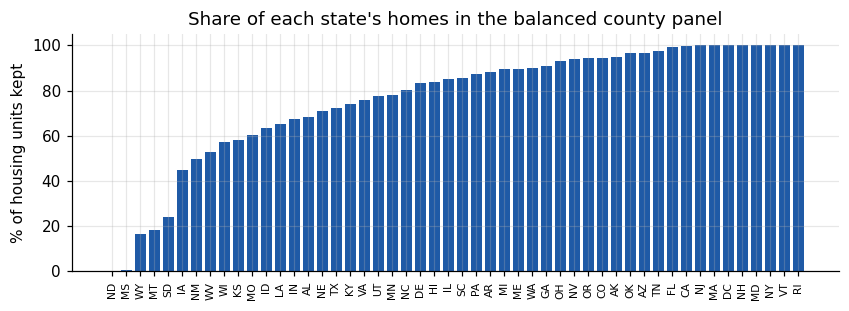

In [3]:
cov_state = coverage[coverage["unique_id"].str.startswith("ST:")].sort_values("hu_coverage")
fig, ax = plt.subplots(figsize=(9, 2.8))
ax.bar(cov_state["unique_id"].str[3:], 100 * cov_state["hu_coverage"], color=COLORS["ours"])
ax.set_ylabel("% of housing units kept")
ax.set_ylim(0, 105)
ax.tick_params(axis="x", labelsize=7, rotation=90)
ax.set_title("Share of each state's homes in the balanced county panel")
save(fig, "01_state_coverage")

## 2. Joins: counties that did not match a Census housing-unit count

Matching is on state + normalised county name. Known mismatch: Connecticut replaced its 8
counties with 9 planning regions in Census products from 2022; if Zillow still reports the old
counties, they cannot be weighted and drop out.

In [4]:
pd.Series(audit["unmatched_counties_by_state"], name="unmatched counties").to_frame()

,unmatched counties
CT,8
ND,1


## 3. Coherence gap: rebuilt series vs Zillow's published ones

Compared for the nation and for nodes where the panel holds at least 95% of the housing units.
Metros made of a single county are listed separately: there the rebuilt series *is* Zillow's
county series, so agreement is automatic and says nothing. Three numbers per node:
* **level gap**: our typical value vs Zillow's, last month (expected to differ: unit vs value weights);
* **growth correlation** of month-on-month changes;
* **growth RMSE** in percentage points, monthly and year-on-year. This is the error we would
  carry into every forecast just from rebuilding the series, so it is a floor to compare
  forecast errors against.

In [5]:
gap = checks.coherence_gap(Y, pub, coverage, nodes)
write_metrics("01_coherence_gap", gap)
gap["group"] = np.where((gap["level"] == "Metro") & (gap["n_counties"] == 1), "Metro (1 county)",
                        np.where(gap["level"] == "Metro", "Metro (2+ counties)", gap["level"]))
summary = gap.groupby("group").agg(
    nodes=("unique_id", "size"),
    median_level_gap_pct=("level_gap_pct_last", "median"),
    median_growth_corr=("growth_corr_1m", "median"),
    median_rmse_1m_pp=("growth_rmse_1m_pp", "median"),
    median_rmse_12m_pp=("growth_rmse_12m_pp", "median"),
).reindex(["National", "State", "Metro (2+ counties)", "Metro (1 county)"]).dropna(how="all")
write_metrics("01_coherence_summary", summary.reset_index())
summary.round(3)

,nodes,median_level_gap_pct,median_growth_corr,median_rmse_1m_pp,median_rmse_12m_pp
group,,,,,
National,1,24.610,0.978,0.134,1.167
State,13,2.605,0.996,0.048,0.336
Metro (2+ counties),112,0.037,0.997,0.050,0.285
Metro (1 county),327,0.001,1.000,0.001,0.011


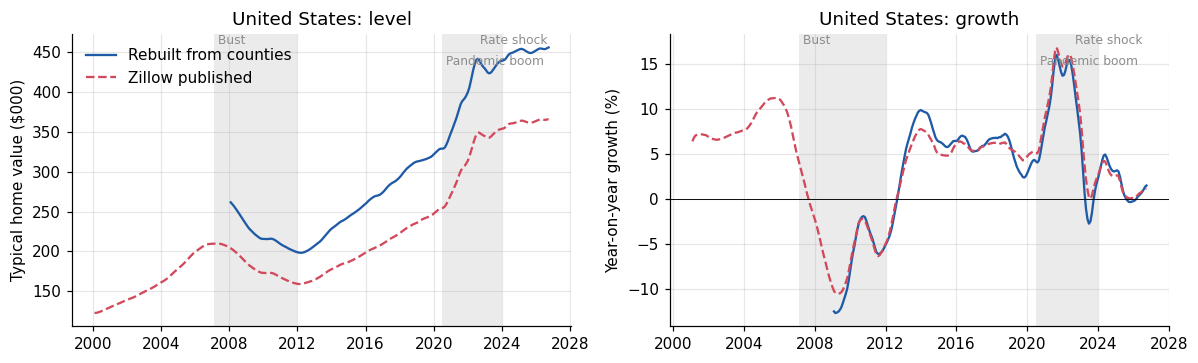

In [6]:
us = Y[Y["unique_id"] == "US"].set_index("ds")["typical_value"]
zus = checks.published_ids(pub).query("unique_id == 'US'").set_index("date")["zhvi"]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
axes[0].plot(us.index, us / 1e3, color=COLORS["ours"], label="Rebuilt from counties")
axes[0].plot(zus.index, zus / 1e3, color=COLORS["zillow"], label="Zillow published", ls="--")
axes[0].set_ylabel("Typical home value ($000)")
axes[0].set_title("United States: level")
axes[0].legend(frameon=False)
g_ours, g_z = 100 * np.log(us).diff(12), 100 * np.log(zus).diff(12)
axes[1].plot(g_ours.index, g_ours, color=COLORS["ours"])
axes[1].plot(g_z.index, g_z, color=COLORS["zillow"], ls="--")
axes[1].axhline(0, color="k", lw=0.6)
axes[1].set_ylabel("Year-on-year growth (%)")
axes[1].set_title("United States: growth")
for ax in axes:
    shade_regimes(ax)
fig.tight_layout()
save(fig, "01_us_rebuilt_vs_published")

,unique_id,level,n_counties,hu_coverage,level_gap_pct_last,growth_corr_1m,growth_rmse_1m_pp,growth_rmse_12m_pp,group
273,"MSA:New York, NY",Metro,22,0.995,8.878,0.834,0.258,2.435,Metro (2+ counties)
376,"MSA:St. Cloud, MN",Metro,2,1.000,-0.019,0.882,0.323,2.150,Metro (2+ counties)
219,"MSA:Logan, UT",Metro,2,1.000,0.040,0.936,0.281,1.808,Metro (2+ counties)
258,"MSA:Morristown, TN",Metro,3,1.000,0.065,0.790,0.461,1.691,Metro (2+ counties)
368,"MSA:Shreveport, LA",Metro,3,1.000,0.085,0.888,0.220,1.586,Metro (2+ counties)
150,"MSA:Glenwood Springs, CO",Metro,2,1.000,43.184,0.960,0.199,1.534,Metro (2+ counties)
271,"MSA:New Orleans, LA",Metro,6,0.954,0.454,0.904,0.225,1.509,Metro (2+ counties)
97,"MSA:Cumberland, MD",Metro,2,1.000,-0.425,0.937,0.377,1.256,Metro (2+ counties)
36,"MSA:Batesville, AR",Metro,2,1.000,1.095,0.906,0.205,1.253,Metro (2+ counties)
94,"MSA:Crestview, FL",Metro,2,1.000,7.486,0.987,0.149,1.172,Metro (2+ counties)


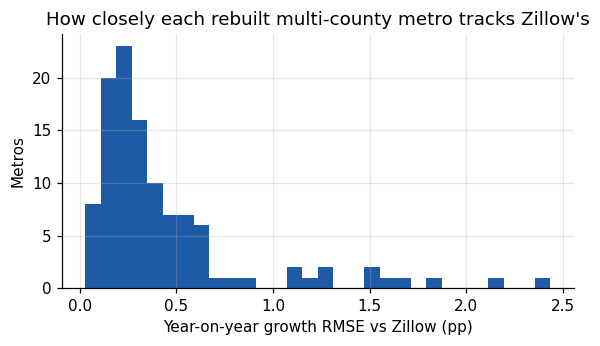

In [7]:
metros = gap[gap["group"] == "Metro (2+ counties)"]
fig, ax = plt.subplots(figsize=(6, 3))
ax.hist(metros["growth_rmse_12m_pp"], bins=30, color=COLORS["ours"])
ax.set_xlabel("Year-on-year growth RMSE vs Zillow (pp)")
ax.set_ylabel("Metros")
ax.set_title("How closely each rebuilt multi-county metro tracks Zillow's")
save(fig, "01_metro_gap_hist")
metros.sort_values("growth_rmse_12m_pp", ascending=False).head(10).round(3)

**Reading the US figure.** The level gap is mostly composition: the counties without a full
history since 2008 are mostly small and rural, where homes are cheaper, so the panel's
"typical home" is pricier than the nation's. Growth, which is what gets forecast, lines up much
more closely, apart from 2013-14, when the coastal metros that dominate the panel recovered faster.

## 4. What is being forecast

Month-on-month log growth of the housing-stock value, by level. Counties are noisier than
metros, metros than states: the usual reason reconciliation helps, since the smoother upper
levels can steady the noisy bottom.

In [8]:
Y = Y.sort_values(["unique_id", "ds"])
Y["growth_pct"] = 100 * Y.groupby("unique_id")["y"].transform(lambda s: np.log(s).diff())
Y["level"] = Y["unique_id"].str.split(":").str[0].map({"US": "National", "ST": "State", "MSA": "Metro", "CTY": "County"})
vol = Y.groupby(["level", "unique_id"])["growth_pct"].std().groupby("level").median()
vol = vol.reindex(["National", "State", "Metro", "County"]).rename("median monthly growth s.d. (pp)")
write_metrics("01_volatility_by_level", vol.reset_index())
vol.round(3).to_frame()

,median monthly growth s.d. (pp)
level,
National,0.618
State,0.545
Metro,0.616
County,0.650
